### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_IOQUOILQCSGX


### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from scipy import signal
from nptdms import TdmsFile
import h5py
import cv2
import glob, os
from roifile import roiread
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from scipy.interpolate import griddata

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
### PARAMETERS ####
UM_PER_PIXEL = 0.52

In [6]:
#### path to relevant files
savedir = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/plots"

imgfile = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/run1/mcorr_nonrigid_denoised/denoised.h5"
templatefile = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
roifile = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/ROI_yutaka_renamed.zip"
dfffile = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/dff_ROI_yutaka/DFF.hdf5"
# syncfile = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20241018_rec11/rec11_cropped.tdms"

### Load data

In [7]:
with h5py.File(imgfile, "r") as hf:
    mov = hf["data"][:]
print(mov.shape)

(3580, 512, 512)


In [8]:
with h5py.File(dfffile, "r") as hf:
    Y = hf["dff"][:, ::50]
# Y = ndi.uniform_filter1d(Y, size=5, axis=1)
print(Y.shape)

(91, 4860)


In [9]:
template = cv2.imread(templatefile, -1)

In [10]:
rois = roiread(roifile)
rois = sorted(rois, key=lambda x: x.name)  # sort the list
contours = [r.subpixel_coordinates.astype("int") for r in rois]
coms = np.array([r.subpixel_coordinates.mean(axis=0) for r in rois])

### Show cartoon

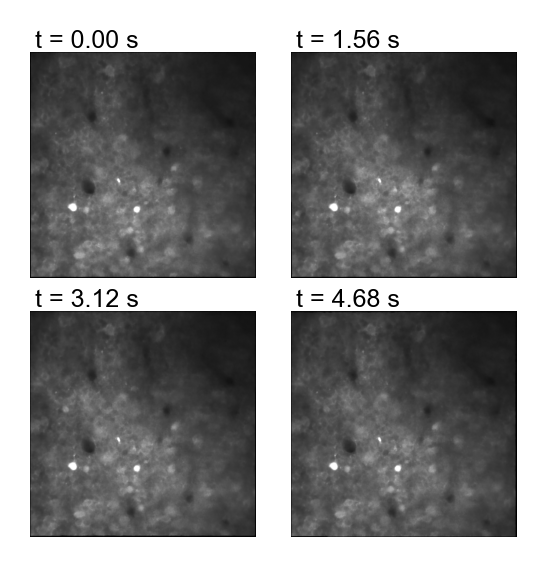

In [11]:
fig = plt.figure(figsize=(2.1,2.1), dpi=300)
gs = fig.add_gridspec(2, 2, wspace=0.15, hspace=0.15)

for i in range(4):
    ax = fig.add_subplot(gs[i//2, i%2])
    ax.imshow(mov[1160 + i * 24], aspect="equal", vmin=10, vmax=4000, cmap="gray")
    ax.text(10, -10, f"t = {i*24/15.4:.2f} s", color="k", fontsize=6)
    ax.axis("off")

plt.savefig(os.path.join(tmpdir, "cartoon.pdf"))
plt.show()

### Analysis

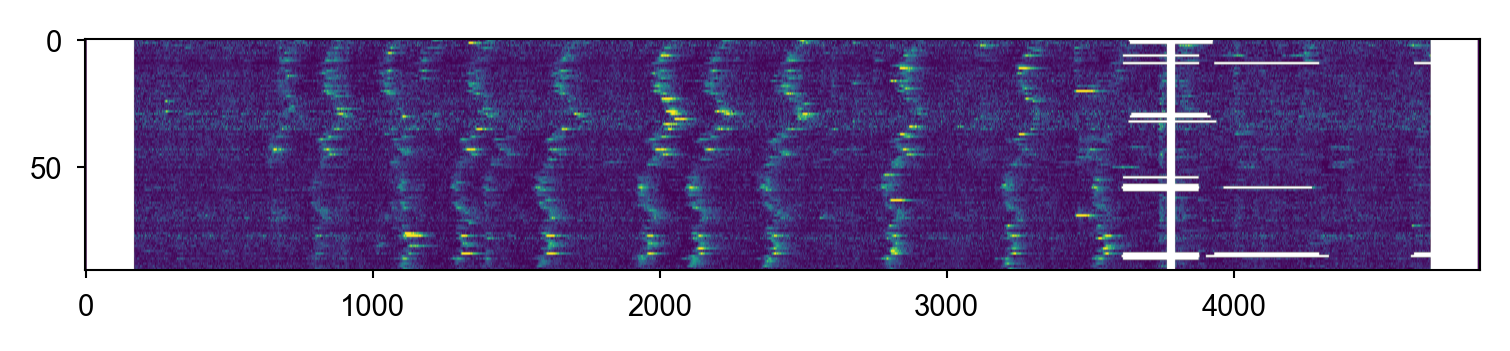

In [12]:
fig, ax = plt.subplots(figsize=(6,1), dpi=300)
ax.imshow(Y, aspect="auto", vmin=0, vmax=1)
plt.show()

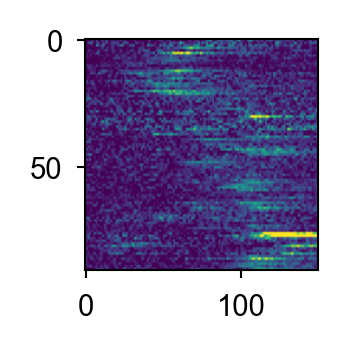

In [13]:
fig, ax = plt.subplots(figsize=(1,1), dpi=300)
ax.imshow(Y[:, 1000:1150], aspect="auto", vmin=0, vmax=1)
plt.show()

In [14]:
events = [
    {"start": 630, "end": 760, "mix": False},
    {"start": 800, "end": 920, "mix": False},
    {"start": 1020, "end": 1150, "mix": False},
    {"start": 1250, "end": 1450, "mix": False},
    {"start": 1550, "end": 1750, "mix": False},
    {"start": 1900, "end": 2100, "mix": True},
    {"start": 2090, "end": 2300, "mix": False},
    {"start": 2350, "end": 2550, "mix": False},
    {"start": 2750, "end": 2950, "mix": False},
    {"start": 3180, "end": 3380, "mix": False},
    {"start": 3480, "end": 3630, "mix": False},
]

0


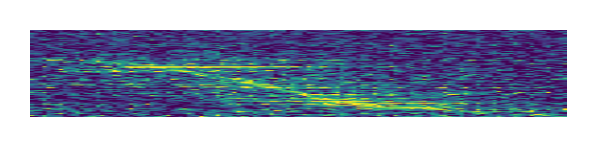

1


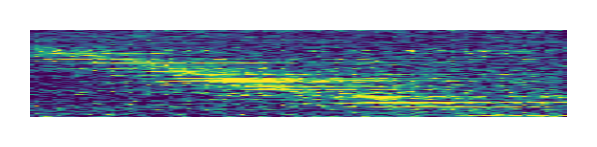

2


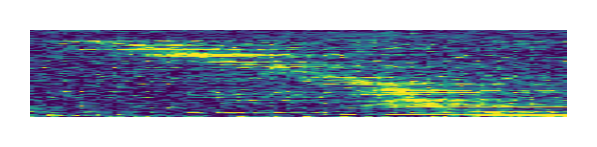

3


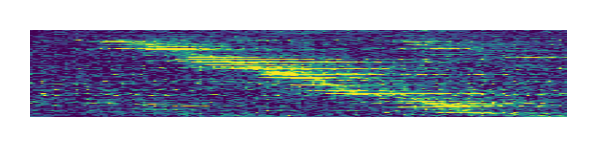

4


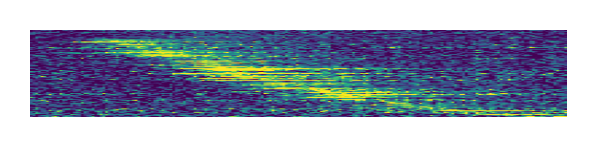

5


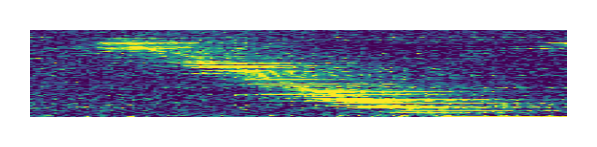

6


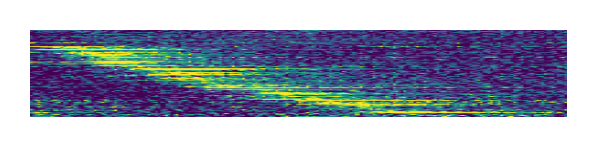

7


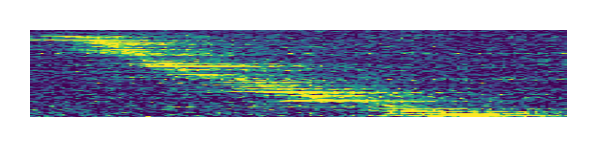

8


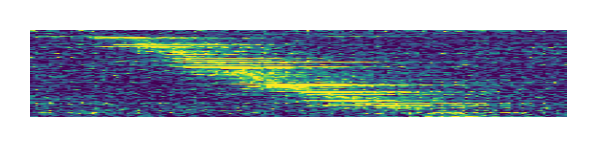

9


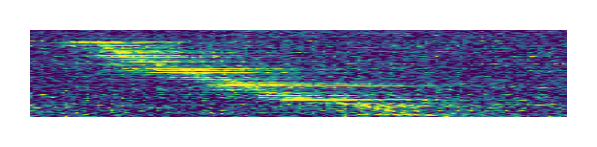

10


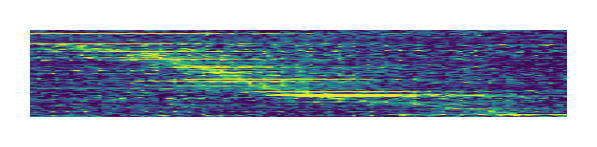

In [15]:
df = []
for (k, e) in enumerate(events):
    print(k)
    d = Y[:, e["start"]:e["end"]]
    peaks = []
    for nid in range(d.shape[0]):
        y = d[nid].copy()
        y[np.isnan(y)] = 0
        y = ndi.uniform_filter1d(y, size=5)
        peak = np.argmax(y)
        if y[peak] < 0.25:
            peak = 0
        peaks.append(peak)
        df.append({
            "neuron": nid,
            "event": k,
            "peak": peak
        })
    peaks = np.array(peaks)

    d2 = d[np.argsort(peaks)]
    d2[np.isnan(d2)] = 0
    fig, ax = plt.subplots(figsize=(2,0.5), dpi=300)
    ax.imshow(d2, aspect="auto", vmin=0, vmax=0.5)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

df = pd.DataFrame(df)

In [16]:
df["peak_time"] = df["peak"] * 0.05 # in seconds
for nid in range(Y.shape[0]):
    idx = df[df["neuron"] == nid].index
    df.loc[idx, "x"] = coms[nid, 0] * UM_PER_PIXEL
    df.loc[idx, "y"] = coms[nid, 1] * UM_PER_PIXEL
for e in range(len(events)):
    df_filtered = df[(df["event"] == e) & (df["peak"] > 0)]
    rank = df_filtered['peak'].rank(method='min')
    df.loc[df_filtered.index, "rank"] = rank
display(df)

,neuron,event,peak,peak_time,x,y,rank
0,0,0,106,5.30,37.586250,21.406664,57.0
1,1,0,98,4.90,51.649998,22.189999,55.0
2,2,0,103,5.15,45.962219,40.299999,56.0
3,3,0,52,2.60,34.298332,49.735832,26.0
4,4,0,82,4.10,51.139999,74.239998,51.0
...,...,...,...,...,...,...,...
996,86,10,59,2.95,15.186363,220.515442,39.0
997,87,10,65,3.25,26.631428,205.520706,45.0
998,88,10,51,2.55,38.759998,208.349991,27.0
999,89,10,40,2.00,53.429996,215.753555,18.0


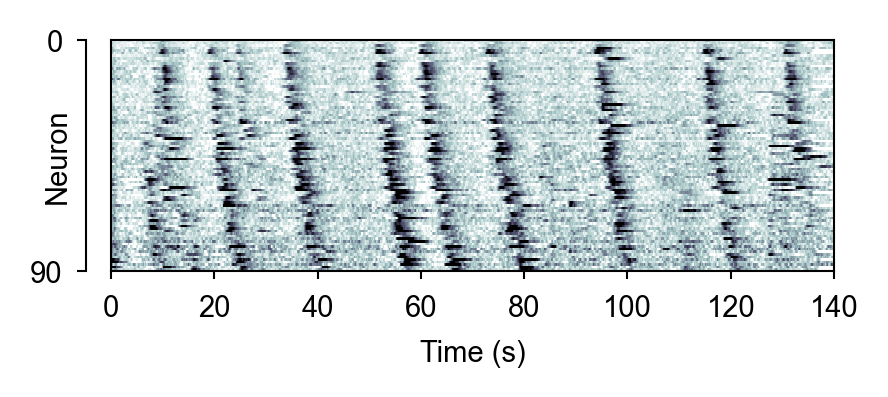

In [28]:
r = df.groupby("neuron")["rank"].sum().to_numpy()
neuron_order = np.argsort(r)

d2 = Y[neuron_order].copy()
d2 = d2[r>0]
d2 = d2[:, 900:4200]
d2[np.isnan(d2)] = 0
d2 = ndi.uniform_filter1d(d2, size=10)
t = np.arange(d2.shape[1]) * 0.05

fig = plt.figure(figsize=(3.25, 1.0), dpi=300)
gs = fig.add_gridspec(1, 2, width_ratios=[0.02, 1], wspace=0.05,)

ax = fig.add_subplot(gs[0, 1])
im = ax.imshow(d2, aspect="auto", vmin=0, vmax=0.5, cmap="bone_r", interpolation="nearest", extent=(t[0], t[-1], d2.shape[0], 0))
ax.set_xlabel("Time (s)")
ax.set_yticks([])
ax.set_xlim(0, 140)
# cax = ax.inset_axes([0.4, 1.3, 0.2, 0.05])
# colbar = fig.colorbar(im, cax=cax, orientation="horizontal")

ax = fig.add_subplot(gs[0, 0])
ax.set_aspect(10)
ax.set_ylabel("Neuron", labelpad=-10)
ax.set_yticks([0, d2.shape[0]])
ax.set_ylim([0, d2.shape[0]])
ax.set_xticks([])
ax.invert_yaxis()
for sp in ["top", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "sequence.pdf"))
plt.show()

In [28]:
def plot_wave(df, column_name, template_img, contours, vmin=None, vmax=None, show_cell_id=False, hide_bad_cells=True,
              img_vmin=None, img_vmax=None, cmap_name="viridis", figsize=(3,3),
              figsavename=None, pixel_size_um=0.52, real_length_um=50):

    values = df[column_name].to_numpy()
    if vmin is None:
        vmin = np.percentile(values[values>0], 1)
    if vmax is None:
        vmax = np.percentile(values[values>0], 98)

    coms = [e.mean(axis=0) for e in contours]

    # prepare a color map
    base_cmap = plt.get_cmap(cmap_name)
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    custom_color_map = lambda val: base_cmap(norm(val))

    colors = []
    for (i, r) in df.iterrows():
        v = r[column_name]
        if v == 0:
            c = [0, 0, 0]
        else:
            c = custom_color_map(v)
            c = [int(255 * v) for v in c]
        colors.append(c)

    img = template_img.copy().astype("float")
    if img_vmin is None:
        img_vmin = np.percentile(img, 1)
    if img_vmax is None:
        img_vmax = np.percentile(img, 99)
    img = 255 * (img - img_vmin) / (img_vmax - img_vmin)
    img = np.clip(img, 0, 255).astype("uint8")
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    for i, c in enumerate(contours):
        if hide_bad_cells:
            if not np.all(colors[i] == [0,0,0]):
                cv2.drawContours(img, contours, contourIdx=i, color=colors[i], thickness=2, lineType=cv2.LINE_AA)
        else:
            cv2.drawContours(img, contours, contourIdx=i, color=colors[i], thickness=2, lineType=cv2.LINE_AA)
        if show_cell_id:
            n = df.loc[i, "neuron"]
            cv2.putText(img, f"{n}", (int(coms[i][0]), int(coms[i][1])), cv2.FONT_HERSHEY_DUPLEX, 0.5, (255,255,255))

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.imshow(img)

    # show scalebar
    scalebar = AnchoredSizeBar(ax.transData,
                               real_length_um / pixel_size_um,
                               f'{real_length_um} µm',
                               'lower left', pad=0.2, color='white',
                               frameon=False, label_top=True, size_vertical=4)
    ax.add_artist(scalebar)
    ax.axis("off")

    # show colorbar
    # cax = ax.inset_axes([1.04, 0.2, 0.05, 0.6])
    # colbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=base_cmap), cax=cax, orientation="vertical")
    cax = ax.inset_axes([0.2, -0.1, 0.6, 0.05])
    colbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=base_cmap), cax=cax, orientation="horizontal")

    # annotate axis
    ax.annotate("", xy=(0.8, 1.05), xytext=(0.2, 1.05), 
                xycoords='axes fraction',
                arrowprops=dict(arrowstyle="<->", color='black'))
    ax.text(0.15, 1.05, "L", va='center', ha='center', transform=ax.transAxes)
    ax.text(0.85, 1.05, "M", va='center', ha='center', transform=ax.transAxes)
    
    ax.annotate("", xy=(-0.05, 0.8), xytext=(-0.05, 0.2), 
                xycoords='axes fraction',
                arrowprops=dict(arrowstyle="<->", color='black'))
    ax.text(-0.05, 0.85, "A", va='center', ha='center', transform=ax.transAxes)
    ax.text(-0.05, 0.15, "P", va='center', ha='center', transform=ax.transAxes)
    if figsavename:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

def fit_vector_field(df, column_name, n_bins=7):
    x = df["x"].to_numpy()
    y = df["y"].to_numpy()
    v = df[column_name].to_numpy()

    x_edges = np.linspace(x.min(), x.max(), n_bins + 1)
    y_edges = np.linspace(y.min(), y.max(), n_bins + 1)

    # Digitize to assign each cell to a bin
    x_bin = np.digitize(x, x_edges) - 1
    y_bin = np.digitize(y, y_edges) - 1

    # Initialize grid
    g = np.full((n_bins, n_bins), np.nan)

    # Fill grid with average azimuth per bin
    for i in range(n_bins):
        for j in range(n_bins):
            mask = (x_bin == i) & (y_bin == j)
            if np.any(mask):
                g[j, i] = np.mean(v[mask])

    # Step 1: Get bin center coordinates
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    X, Y = np.meshgrid(x_centers, y_centers)

    # Step 2: Prepare points and values for interpolation
    valid_mask = ~np.isnan(g)
    points = np.column_stack((X[valid_mask], Y[valid_mask]))
    values = g[valid_mask]

    # Step 3: Interpolate across full grid
    g_interp = griddata(points, values, (X, Y), method='cubic')
    # fill any remaining NaNs (edges) with nearest neighbor
    if np.isnan(g_interp).any():
        g_interp2 = griddata(points, values, (X, Y), method='nearest')
        g_interp[np.isnan(g_interp)] = g_interp2[np.isnan(g_interp)]

    g_smooth = ndi.gaussian_filter(g_interp, sigma=1, mode='nearest')

    # Compute gradient
    dx_um = (x_edges[1] - x_edges[0])  # x-direction bin width in μm
    dy_um = (y_edges[1] - y_edges[0])  # y-direction bin height in μm
    dy, dx = np.gradient(g_smooth, dy_um, dx_um)

    return g_smooth, dx, dy, X, Y

def plot_vector_field(df, retinotopy_map, gx, gy, X, Y, cmap_name="jet", figsize=(4.2,1.8), figsavename=None):
    fig = plt.figure(figsize=figsize, dpi=300)
    gs = fig.add_gridspec(1, 3, width_ratios=[1.5,1,1])
    
    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(retinotopy_map, aspect="equal", extent=[df["x"].min(), df["x"].max(), df["y"].max(), df["y"].min()], cmap='jet')
    cax = ax.inset_axes([0.2, 1.1, 0.6, 0.05])
    colbar = fig.colorbar(im, cax=cax, orientation="horizontal")
    colbar.ax.xaxis.set_ticks_position('top')
    colbar.ax.xaxis.set_label_position('top')
    ax.quiver(X, Y, gx, -gy, scale=0.2, color='k')  # -gy to flip y-axis for image coordinates
    ax.set_xlabel('L → M ($\mathrm{\mu m}$)')
    ax.set_ylabel('P → A ($\mathrm{\mu m}$)')
    
    ax = fig.add_subplot(gs[0, 1])
    grad_amp = np.sqrt(gx**2 + gy**2).flatten()
    grad_amp = 1 / grad_amp
    count, bin_edges = np.histogram(grad_amp, range=[0,250], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
    ax.axvline(np.median(grad_amp), lw=1, color="k", ls="--")
    ax.set_ylabel("count")
    ax.set_xlabel("speed ($\mathrm{\mu m}$/s)")
    # ax.set_xlim([0,0.1])
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)

    ax = fig.add_subplot(gs[0, 2])
    theta = np.arctan2((-1) * gy.flatten(), gx.flatten())
    theta[theta < 0] += 2 * np.pi
    theta = np.rad2deg(theta)
    count, bin_edges = np.histogram(theta, range=[0, 360], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
    ax.axvline(np.median(theta), lw=1, color="k", ls="--")
    ax.set_xlabel("theta")
    ax.set_ylabel("count")
    ax.set_xlim([0, 360])
    ax.set_xticks([0, 180, 360])
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)

    plt.tight_layout()
    if figsavename:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

    return theta, grad_amp

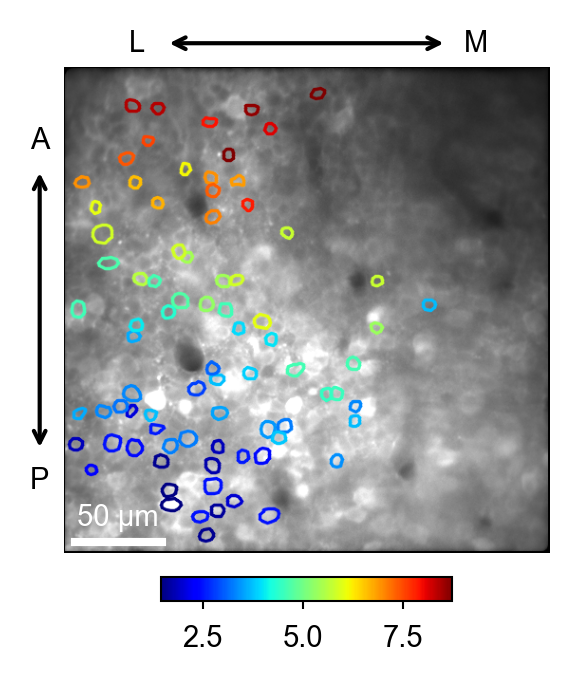

In [29]:
df_filtered = df[df["event"] == 4]
plot_wave(df_filtered, "peak_time", template, contours, cmap_name="jet",
          figsize=(2.1, 2.1), figsavename=os.path.join(tmpdir, "wave_heatmap.pdf"))

0


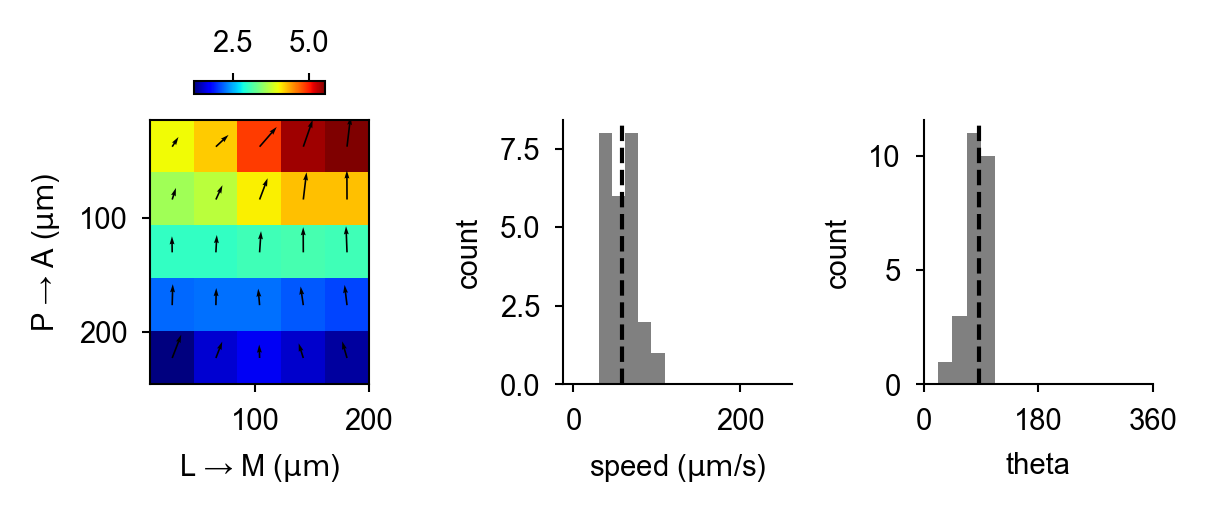

1


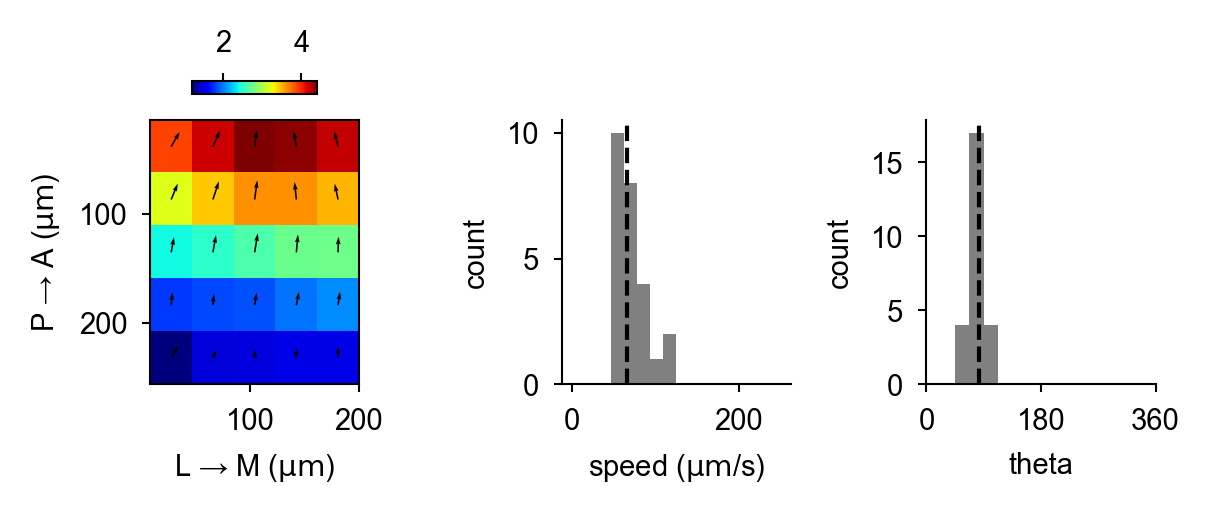

2


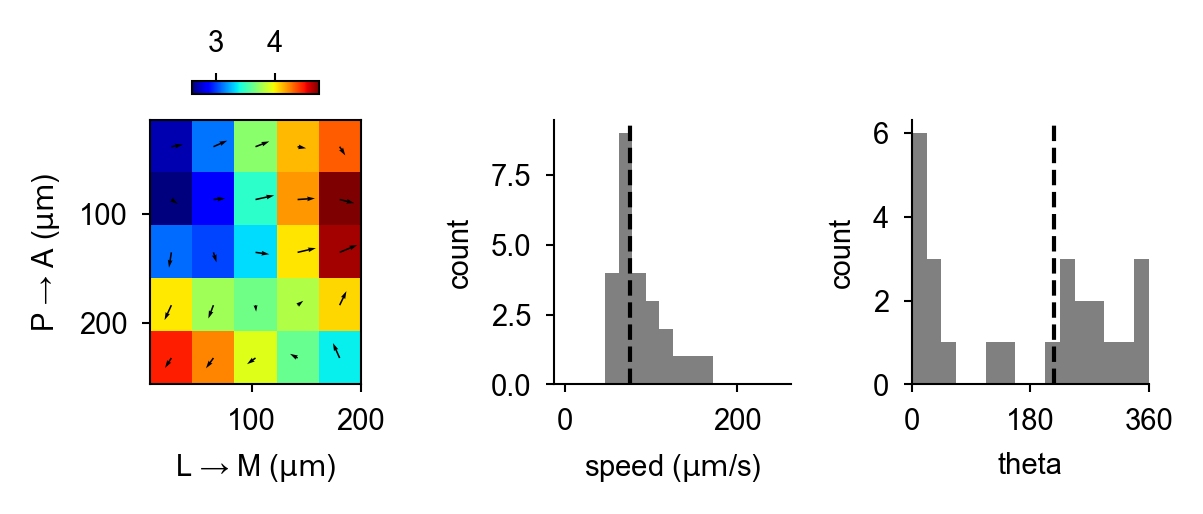

3


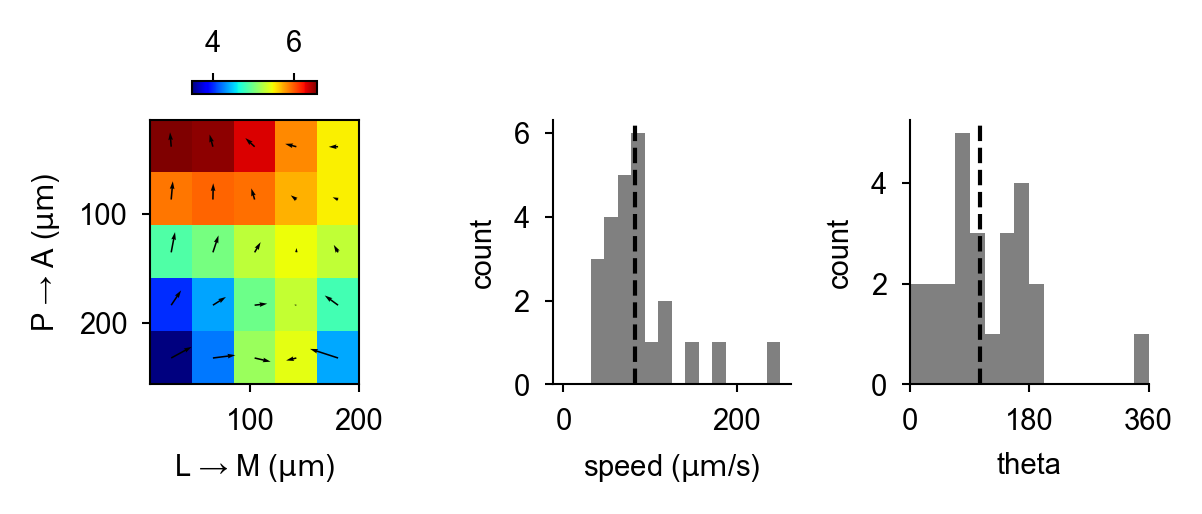

4


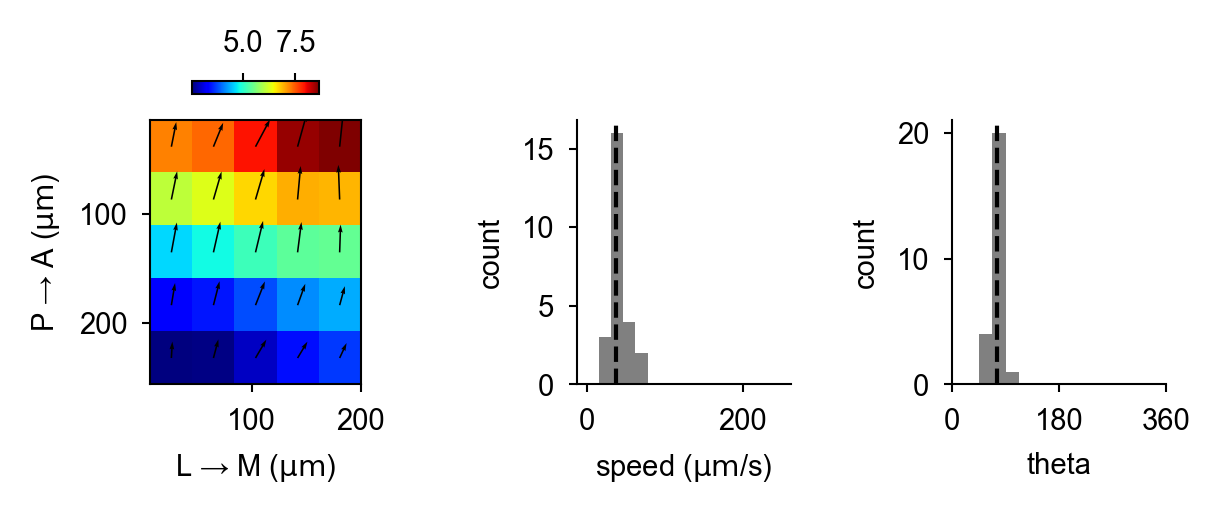

5


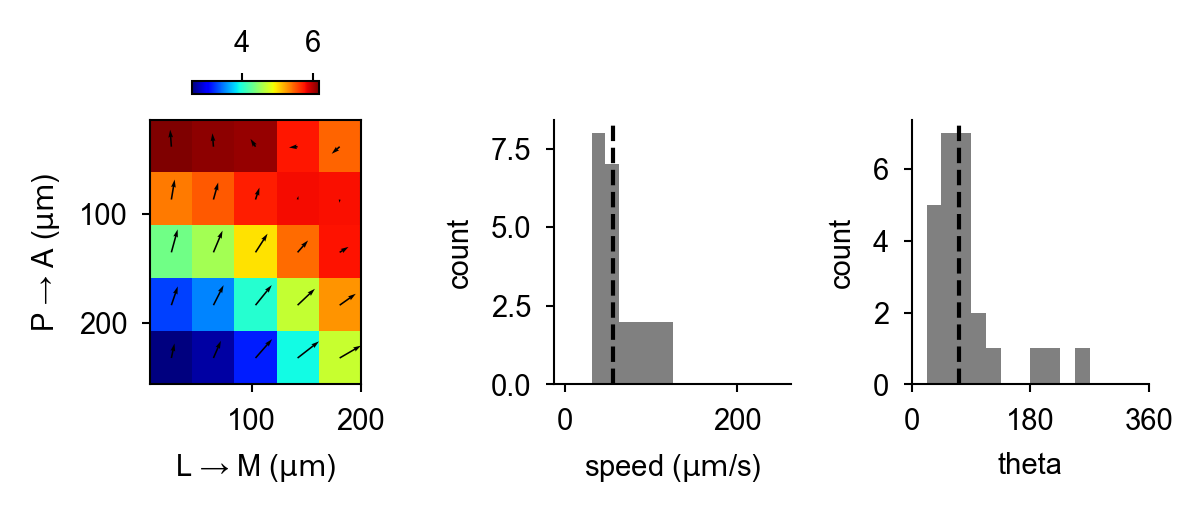

6


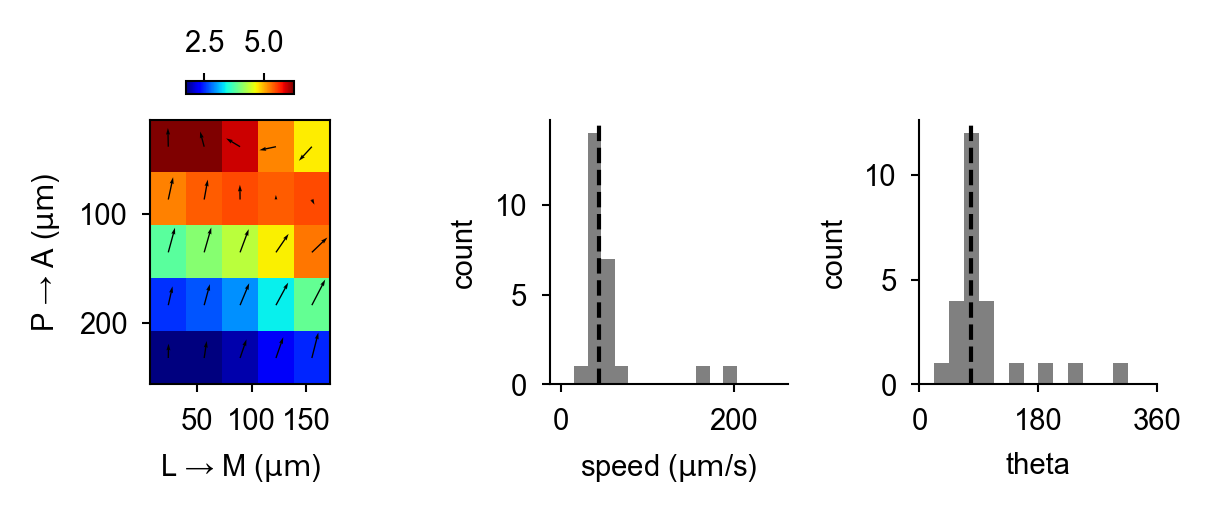

7


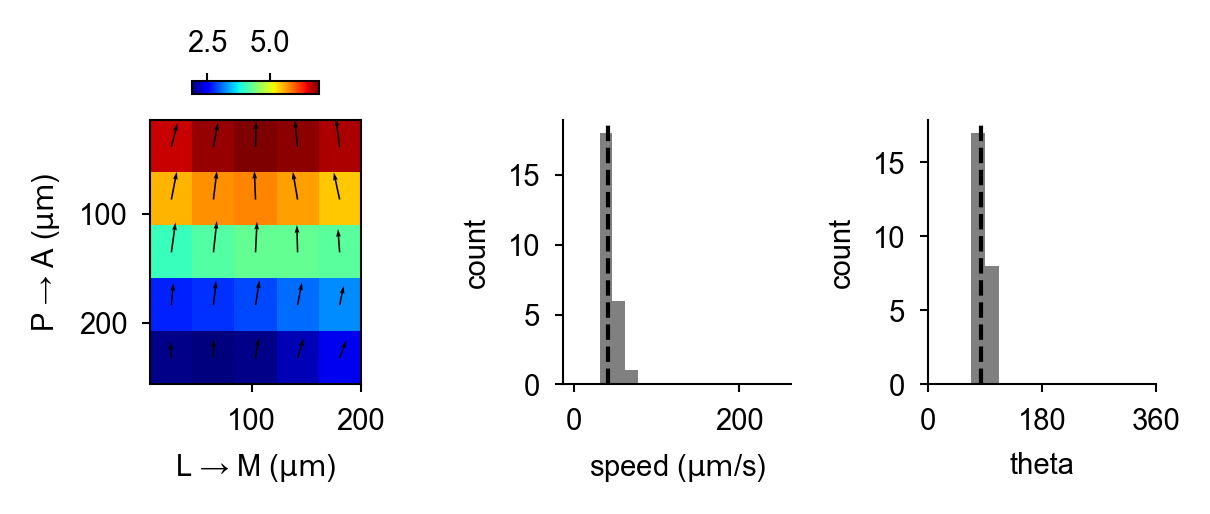

8


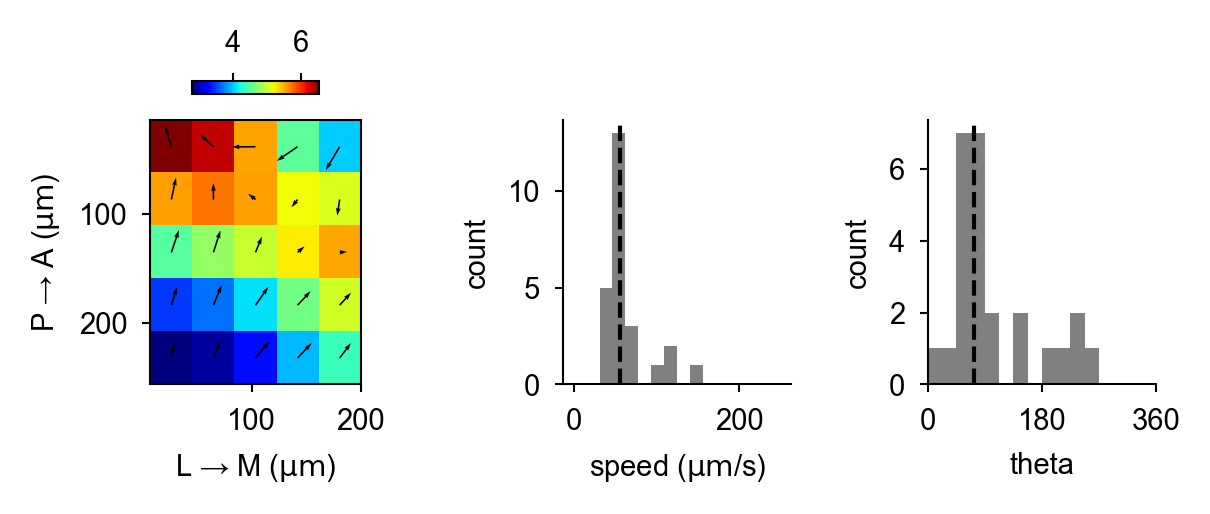

9


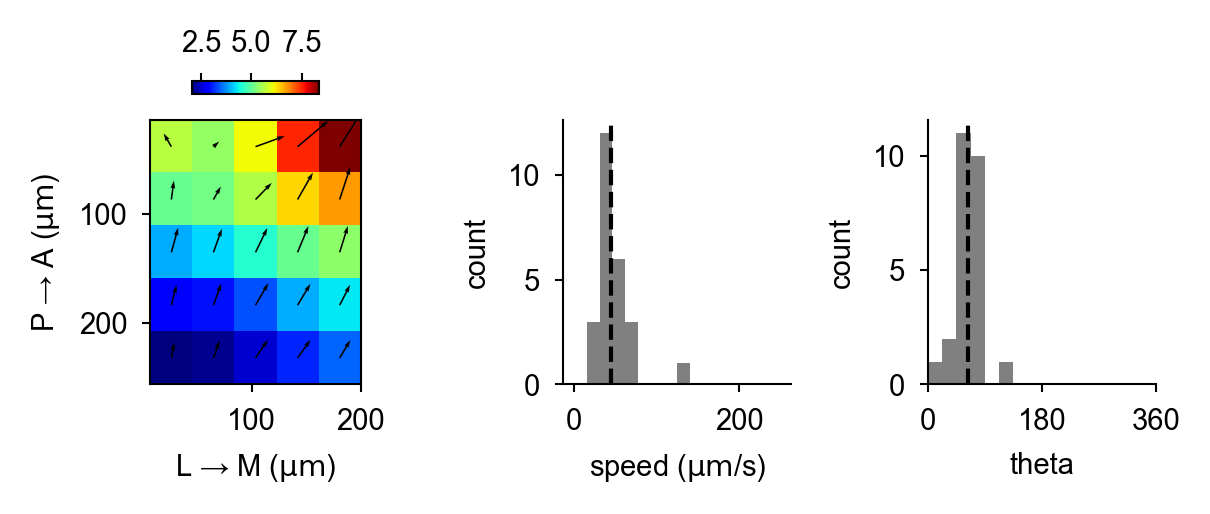

10


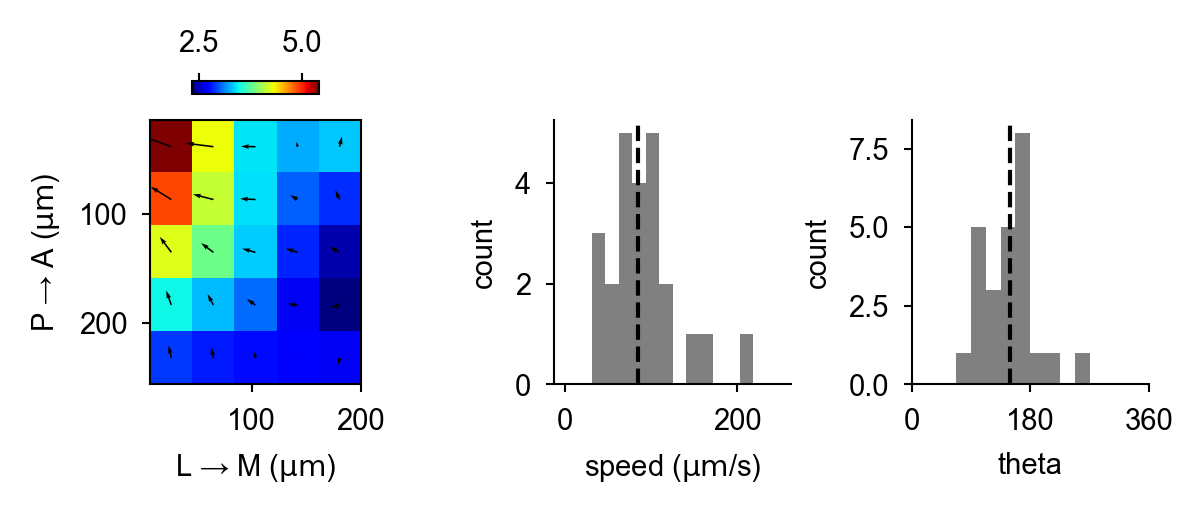

In [20]:
thetas = []
speeds = []
for e in range(len(events)):
    print(e)
    df_filtered = df[(df["event"] == e) & (df["peak_time"] > 0)]
    vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(df_filtered, "peak_time", n_bins=5)
    a, b = plot_vector_field(df_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y, figsavename=os.path.join(tmpdir, "vector_field.pdf"))
    thetas.append(a)
    speeds.append(b)

In [21]:
intervals = []
for i in range(len(events)-1):
    intervals.append(events[i+1]["start"] - events[i]["start"])
intervals = np.array(intervals)
intervals = intervals * 0.05 # convert to seconds

In [22]:
thetas = np.array(thetas).flatten()
speeds = np.array(speeds).flatten()

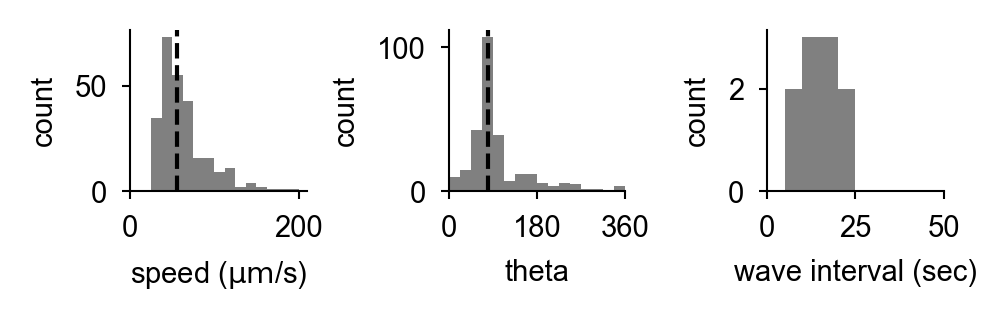

In [23]:
fig = plt.figure(figsize=(3.5,0.7), dpi=300)
gs = fig.add_gridspec(1, 3, width_ratios=[1,1,1], wspace=0.8)

ax = fig.add_subplot(gs[0,0])
count, bin_edges = np.histogram(speeds, range=[0,200], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
ax.axvline(np.median(speeds), lw=1, color="k", ls="--")
ax.set_ylabel("count")
ax.set_xlabel("speed ($\mathrm{\mu m}$/s)")
ax.set_xlim(left=0)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[0,1])
count, bin_edges = np.histogram(thetas, range=[0, 360], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
ax.axvline(np.median(thetas), lw=1, color="k", ls="--")
ax.set_xlabel("theta")
ax.set_ylabel("count")
ax.set_xlim([0, 360])
ax.set_xticks([0, 180, 360])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[0,2])
count, bin_edges = np.histogram(intervals, range=(0,50), bins=10, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
ax.set_xlabel("wave interval (sec)")
ax.set_ylabel("count")
ax.set_xlim([0, 50])
# ax.set_xticks([0, 180, 360])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

plt.savefig(os.path.join(tmpdir, "distribution.pdf"))
plt.show()

### Copy data to bucket

In [24]:
np.save(os.path.join(tmpdir, "speeds.npy"), speeds, allow_pickle=False)
np.save(os.path.join(tmpdir, "thetas.npy"), thetas, allow_pickle=False)
np.save(os.path.join(tmpdir, "intervals.npy"), intervals, allow_pickle=False)

In [27]:
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/plots
cp -r /flash/ReiterU/tmp/tomo_THTWQQJJYGXE/* /bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20250303_rec7/plots
